In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:", df.isnull().sum().sum())

Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Missing values: 0


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Keep a copy for later business analysis
df_analysis = df.copy()

# Remove ID/constant columns from clustering features
drop_cols = [
    "EmployeeNumber", "EmployeeCount",
    "Over18", "StandardHours"
]

X = df.drop(
    columns=[c for c in drop_cols if c in df.columns]
).copy()

# Exclude Attrition from clustering inputs.
# We will use it later to analyse retention risk.
X = X.drop(columns=["Attrition"], errors="ignore")

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_processed = preprocessor.fit_transform(X)

# Convert to a dense array for PCA and plotting
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("Original feature count:", X.shape[1])
print("Processed feature count:", X_processed.shape[1])
print("Processed data shape:", X_processed.shape)

Original feature count: 30
Processed feature count: 51
Processed data shape: (1470, 51)


#K-Means clustering

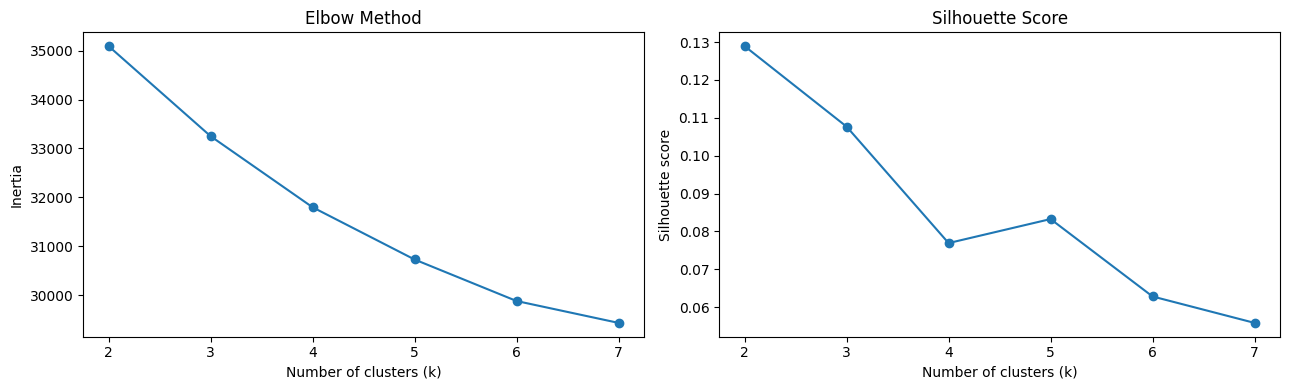

Silhouette scores:
k=2: 0.1289
k=3: 0.1077
k=4: 0.0769
k=5: 0.0833
k=6: 0.0629
k=7: 0.0559


In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_processed)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(
            X_processed, labels,
            sample_size=min(1000, len(X_processed)),
            random_state=42
        )
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

print("Silhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"k={k}: {score:.4f}")

#Hierarchical clustering

In [4]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Use a two-dimensional PCA representation for an interpretable
# hierarchical comparison, while retaining the same employees.
from sklearn.decomposition import PCA

pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_processed)

hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_pca_2d)

print(
    "Hierarchical clustering silhouette score:",
    round(
        silhouette_score(X_pca_2d, hierarchical_labels),
        4
    )
)

Hierarchical clustering silhouette score: 0.3398


#PCA visualization

In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_processed)

print("Features before PCA:", X_processed.shape[1])
print("Components retaining 95% variance:", X_pca.shape[1])
print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Features before PCA: 51
Components retaining 95% variance: 28
Total explained variance: 0.9558


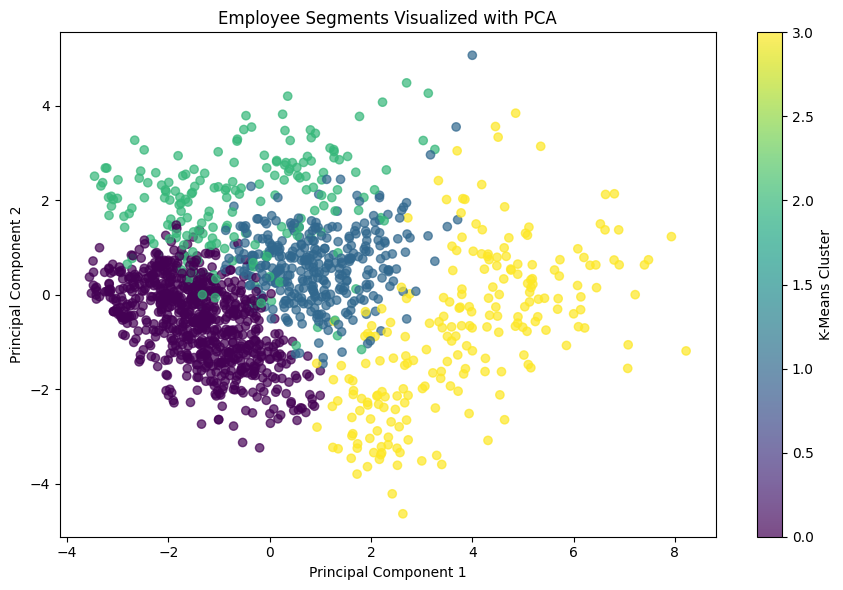

In [6]:
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(X_processed)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.7
)

plt.title("Employee Segments Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="K-Means Cluster")
plt.tight_layout()
plt.show()

#Analyse the workforce segments

In [7]:
# Create a summary table using the original employee data
segmented_df = df_analysis.copy()
segmented_df["Cluster"] = kmeans_labels

cluster_summary = segmented_df.groupby("Cluster").agg(
    Employees=("Cluster", "size"),
    AverageAge=("Age", "mean"),
    AverageMonthlyIncome=("MonthlyIncome", "mean"),
    AverageYearsAtCompany=("YearsAtCompany", "mean"),
    AverageJobSatisfaction=("JobSatisfaction", "mean"),
    AveragePerformanceRating=("PerformanceRating", "mean")
).round(2)

display(cluster_summary)

,Employees,AverageAge,AverageMonthlyIncome,AverageYearsAtCompany,AverageJobSatisfaction,AveragePerformanceRating
Cluster,,,,,,
0,720,34.31,4359.00,3.42,2.72,3.00
1,335,36.21,6154.73,10.35,2.80,3.01
2,197,35.37,5047.76,5.78,2.74,4.00
3,218,48.07,15433.88,14.84,2.65,3.12


In [8]:
# Attrition rate within each cluster
attrition_summary = pd.crosstab(
    segmented_df["Cluster"],
    segmented_df["Attrition"],
    normalize="index"
) * 100

print("Attrition percentage within each cluster:")
display(attrition_summary.round(2))

# Department distribution within clusters
department_summary = pd.crosstab(
    segmented_df["Cluster"],
    segmented_df["Department"]
)

print("Department distribution:")
display(department_summary)

Attrition percentage within each cluster:


Attrition,No,Yes
Cluster,,
0,79.17,20.83
1,90.45,9.55
2,81.22,18.78
3,91.74,8.26


Department distribution:


Department,Human Resources,Research & Development,Sales
Cluster,,,
0,34,472,214
1,9,208,118
2,7,138,52
3,13,143,62


#Performance group analysis

In [9]:
performance_summary = pd.crosstab(
    segmented_df["Cluster"],
    segmented_df["PerformanceRating"],
    normalize="index"
) * 100

print("Performance-rating distribution by cluster (%):")
display(performance_summary.round(2))

Performance-rating distribution by cluster (%):


PerformanceRating,3,4
Cluster,,
0,100.00,0.00
1,99.40,0.60
2,0.00,100.00
3,87.61,12.39


#Build dashboard charts

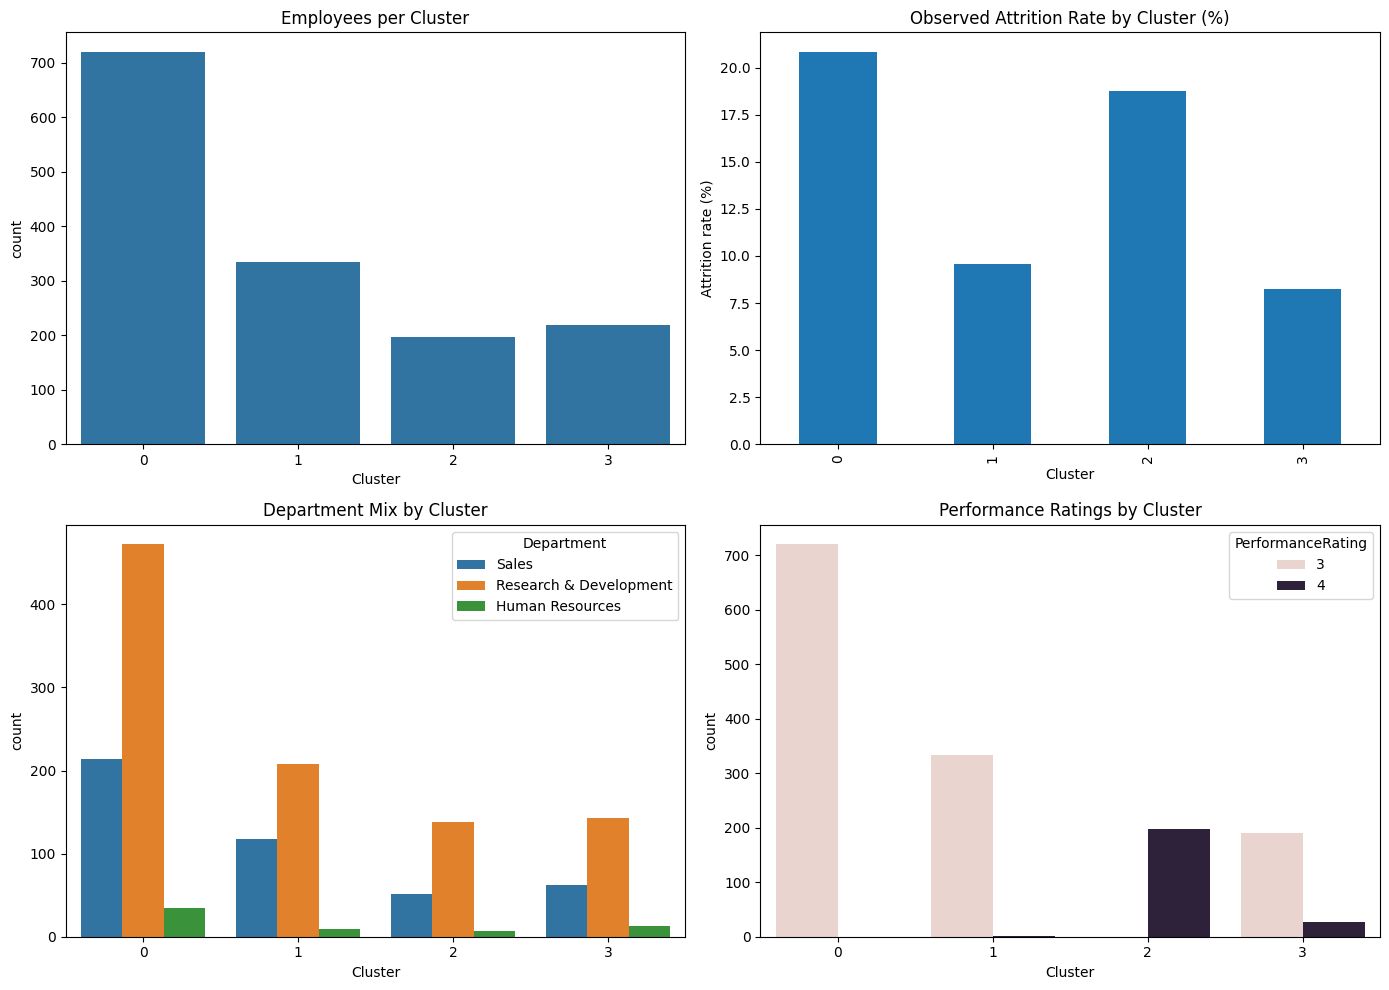

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Cluster sizes
sns.countplot(
    data=segmented_df,
    x="Cluster",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Employees per Cluster")

# Attrition rate by cluster
attrition_rate = segmented_df.assign(
    AttritionFlag=(
        segmented_df["Attrition"].map({"Yes": 1, "No": 0})
    )
).groupby("Cluster")["AttritionFlag"].mean() * 100

attrition_rate.plot(
    kind="bar",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Observed Attrition Rate by Cluster (%)")
axes[0, 1].set_ylabel("Attrition rate (%)")

# Department by cluster
sns.countplot(
    data=segmented_df,
    x="Cluster",
    hue="Department",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Department Mix by Cluster")

# Performance rating by cluster
sns.countplot(
    data=segmented_df,
    x="Cluster",
    hue="PerformanceRating",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Performance Ratings by Cluster")

plt.tight_layout()
plt.show()